In [1]:
import torch 

In [2]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

In [10]:
x = torch.linspace(-2, 2, 50).unsqueeze(1)

In [11]:
x

tensor([[-2.0000],
        [-1.9184],
        [-1.8367],
        [-1.7551],
        [-1.6735],
        [-1.5918],
        [-1.5102],
        [-1.4286],
        [-1.3469],
        [-1.2653],
        [-1.1837],
        [-1.1020],
        [-1.0204],
        [-0.9388],
        [-0.8571],
        [-0.7755],
        [-0.6939],
        [-0.6122],
        [-0.5306],
        [-0.4490],
        [-0.3673],
        [-0.2857],
        [-0.2041],
        [-0.1224],
        [-0.0408],
        [ 0.0408],
        [ 0.1224],
        [ 0.2041],
        [ 0.2857],
        [ 0.3673],
        [ 0.4490],
        [ 0.5306],
        [ 0.6122],
        [ 0.6939],
        [ 0.7755],
        [ 0.8571],
        [ 0.9388],
        [ 1.0204],
        [ 1.1020],
        [ 1.1837],
        [ 1.2653],
        [ 1.3469],
        [ 1.4286],
        [ 1.5102],
        [ 1.5918],
        [ 1.6735],
        [ 1.7551],
        [ 1.8367],
        [ 1.9184],
        [ 2.0000]])

In [15]:
noise = 0.6 * torch.randn_like(x)
y = 3*x + 2 + noise

In [9]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


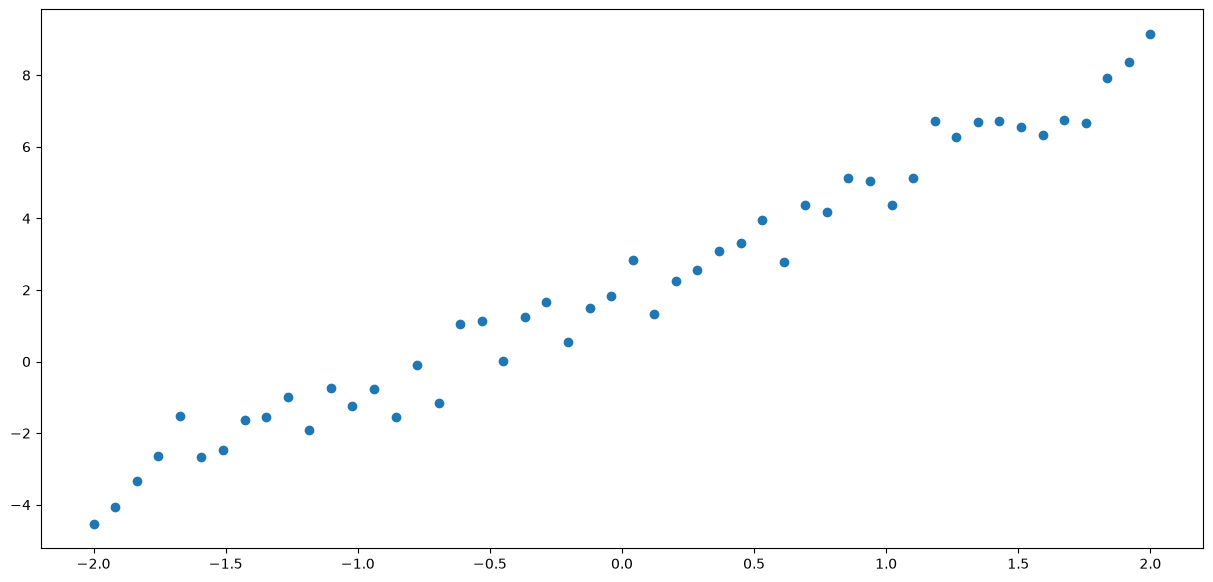

In [16]:
plt.figure(figsize=(15,7))
plt.scatter(x, y)

In [17]:
import torch.nn as nn

In [18]:
model = nn.Linear(1, 1)

In [43]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
epochs = 1000
losses=[]
for epoch in range(epochs):
    y_pred = model(x)
    loss = loss_function(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 100 == 0:
        print(f'Epoch {epoch}/{epochs}, Loss: {loss.item()}')


Epoch 0/1000, Loss: 0.3648432195186615
Epoch 100/1000, Loss: 0.3648429811000824
Epoch 200/1000, Loss: 0.36484295129776
Epoch 300/1000, Loss: 0.3648430109024048
Epoch 400/1000, Loss: 0.3648429811000824
Epoch 500/1000, Loss: 0.3648430109024048
Epoch 600/1000, Loss: 0.3648430109024048
Epoch 700/1000, Loss: 0.3648429811000824
Epoch 800/1000, Loss: 0.3648430109024048
Epoch 900/1000, Loss: 0.3648429811000824


In [32]:
with torch.inference_mode():
    pred = model(x)

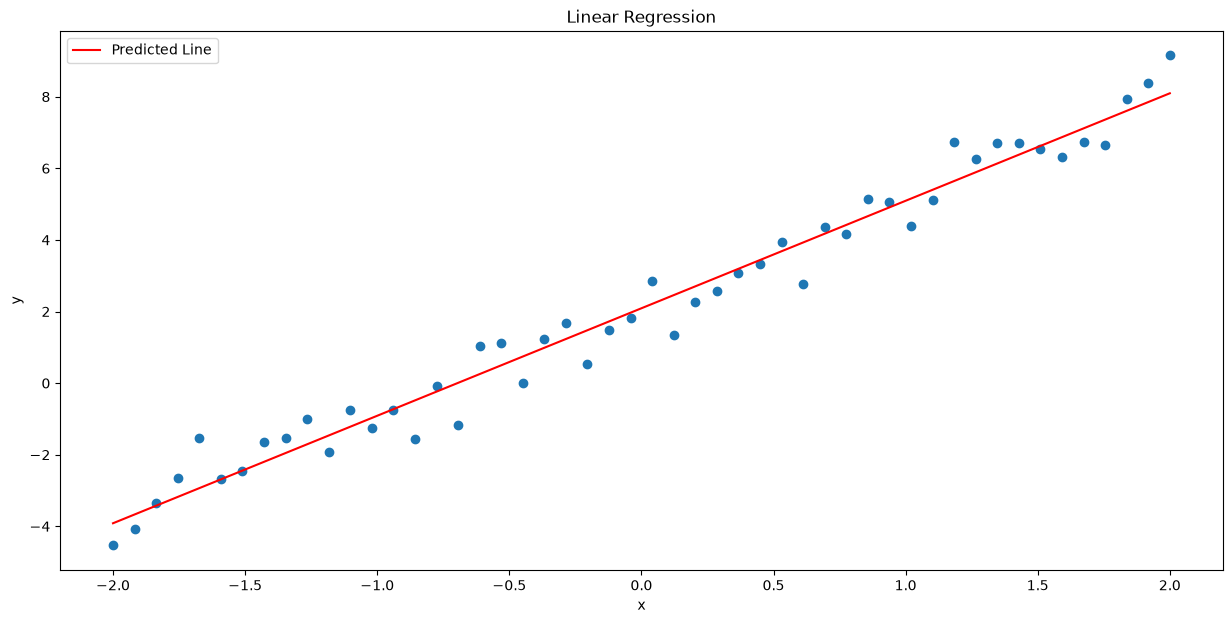

In [33]:
plt.figure(figsize=(15,7))
plt.scatter(x, y)
plt.plot(x, pred, color='red', label='Predicted Line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Linear Regression')
plt.legend()
plt.show()

In [34]:
 from torcheval.metrics import R2Score

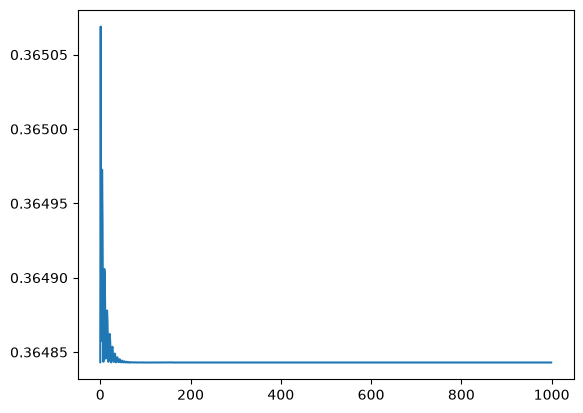

In [44]:
plt.plot(losses)

In [35]:
r2_metric = R2Score()
r2_metric.update(pred, y)   
score = r2_metric.compute()

In [36]:
print(score)

tensor(0.9717)
